In [4]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2




r_seed = 42

from pathlib import Path
WORKDIR = str(Path.cwd().parent) + '/'  # raiz do repositório
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/logs/"+data_hora

In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [5]:
## get dataset

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR + 'Data/processed/activity_recognition_data_custom_concat_phone.csv')

In [6]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,252207666810782,-0.364761,8.793503,1.055084,252207918580802,-0.853210,0.297226,0.890182
1,1600,0,252207717164786,-0.879730,9.768784,1.016998,252207968934806,-0.875137,0.015472,0.162231
2,1600,0,252207767518790,2.001495,11.109070,2.619156,252208019288809,-0.720169,0.388489,-0.284012
3,1600,0,252207817872794,0.450623,12.651642,0.184555,252208069642813,-0.571640,1.227402,-0.241669
4,1600,0,252207868226798,-2.164352,13.928436,-4.422485,252208119996817,-0.380493,1.202835,-0.213135


In [7]:
data.isnull().sum()

pessoa_x              0
atividade             0
tempo_acelerômetro    0
acelerômetro_x        0
acelerômetro_Y        0
acelerômetro_Z        0
tempo_gyro            0
giroscópio_x          0
giroscópio_Y          0
giroscópio_Z          0
dtype: int64

In [8]:
#remove the null class
data=data.dropna()

# **Data Exploration**

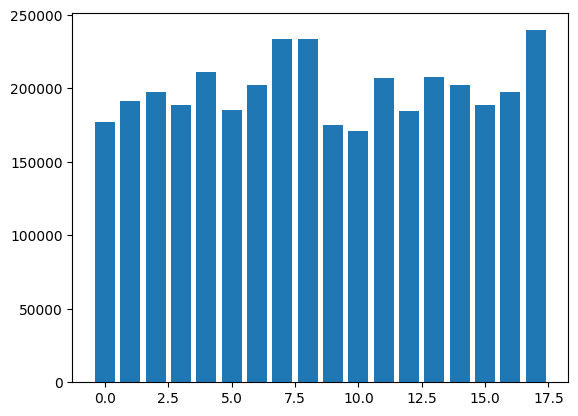

In [9]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

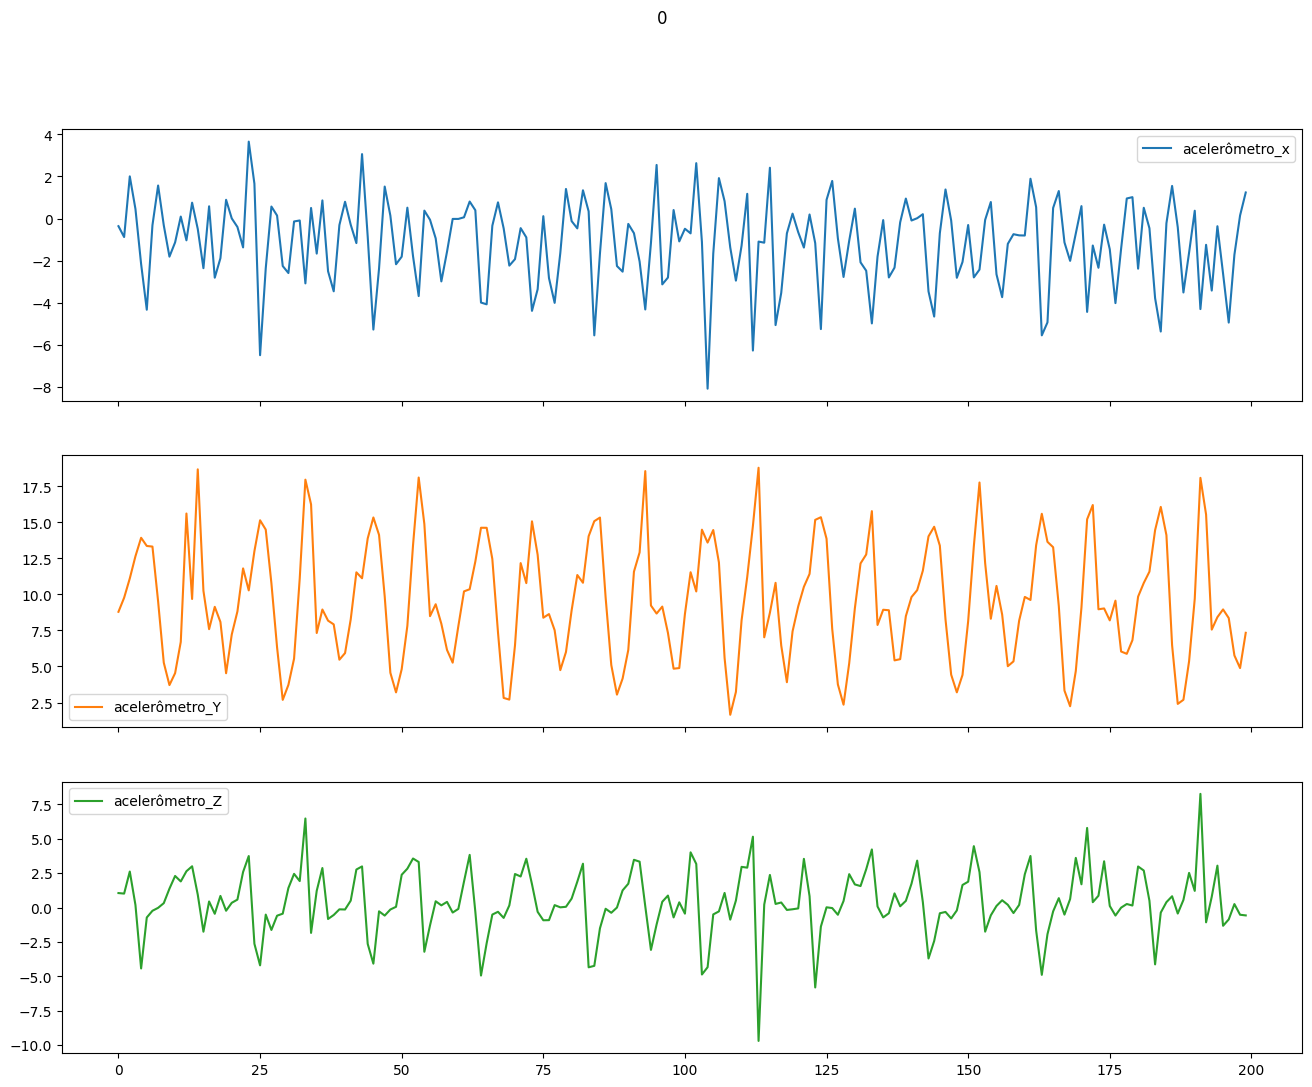

In [10]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

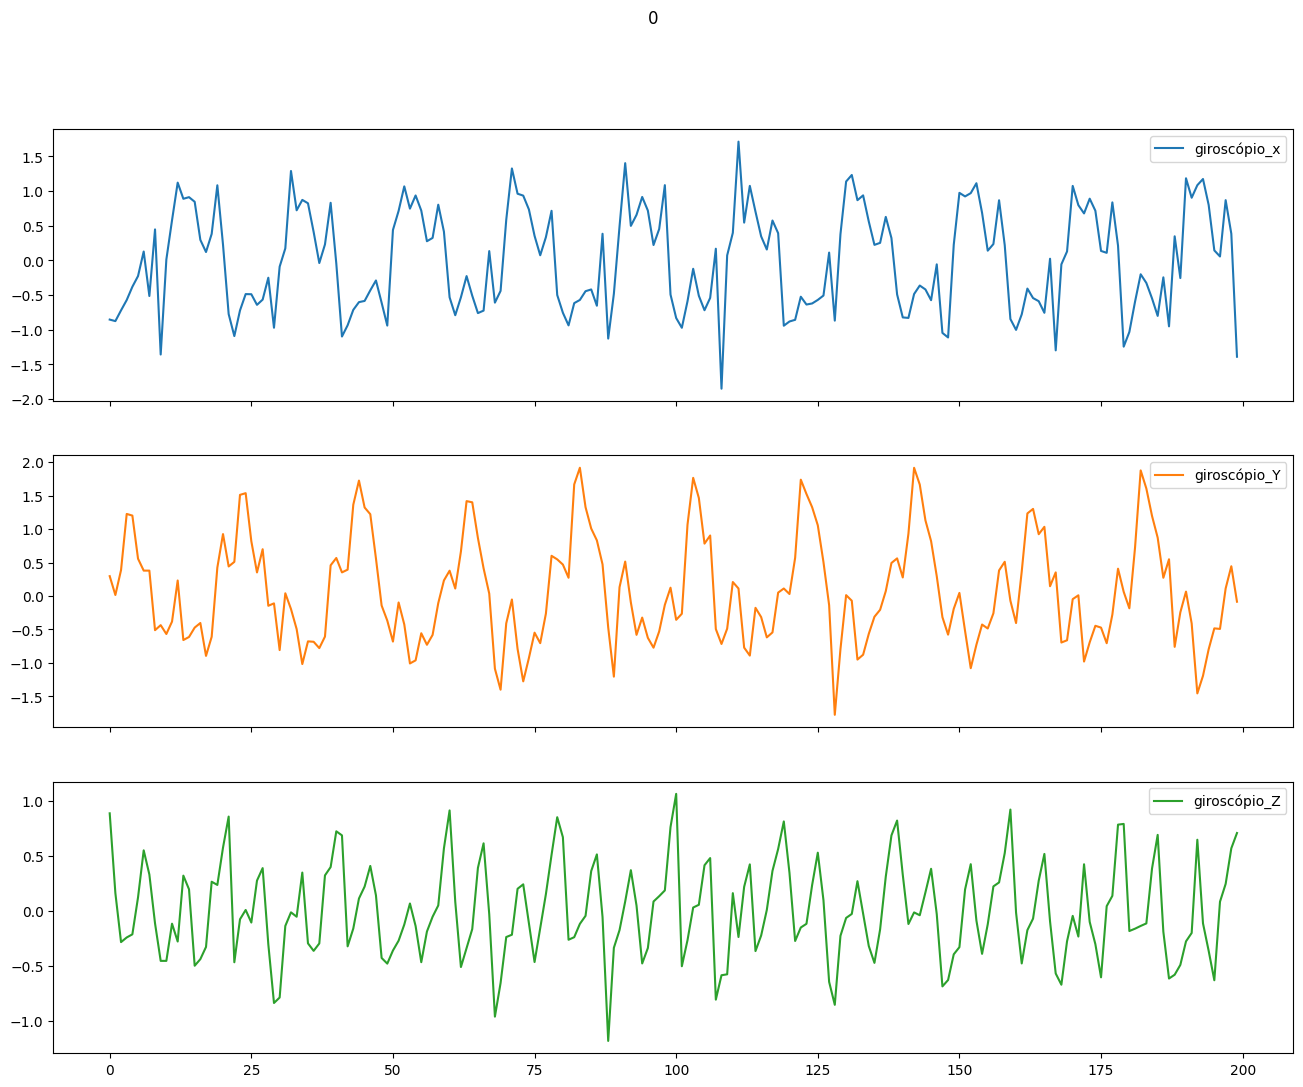

In [11]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

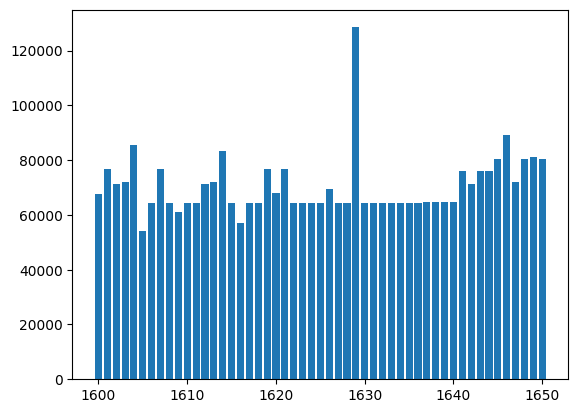

In [12]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [13]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,1,2,3])]

In [ ]:
data.shape

In [ ]:
data.head()

In [ ]:
data = data.reset_index()

In [ ]:
data.head()

In [ ]:
data.shape

# **Models**

In [ ]:
start_validation_index = data[(data['pessoa_x'].isin([1600,1601,1602,1603,1604,1605,1606,1607,1608,1609]))].head(1).index[0]

In [ ]:
print(start_validation_index)

In [ ]:
end_validation_index = data[(data['pessoa_x'].isin([1600,1601,1602,1603,1604,1605,1606,1607,1608,1609]))].tail(1).index[0]

In [ ]:
print(end_validation_index)

In [ ]:
''' index_split_test_and_validation_train = data[(data['pessoa_x'].isin([1600,1601,1602,1603,1604]))].tail(1).index[0]
print(index_split_test_and_validation_train) '''

In [ ]:
''' #Will be used in model training and validation (approx. 90%)
train_validation_indices = []
#Will be used in final test of the model after training (approx. 10%)
test_indices = []


train_validation_indices.extend(data.index[index_split_test_and_validation_train+1:])
test_indices.extend(data.index[:index_split_test_and_validation_train+1])

# Split the dataset without shuffling
print(len(train_validation_indices))
print(len(test_indices))
X_train_validation = data.iloc[train_validation_indices]
X_test = data.iloc[test_indices]


# Print shapes to verify proportions
print("Train/validation set:", X_train_validation.shape)
print("Test set:", X_test.shape) '''

In [ ]:
X_validation_data = data.iloc[start_validation_index:end_validation_index + 1]

In [ ]:
X_validation_data.head()

In [ ]:
X_validation_data.tail()

In [ ]:
#X_validation_data = data.drop(index=data.index[start_validation_index:end_validation_index + 1])

In [ ]:
#_validation_data.head()

In [ ]:
#X_validation_data.tail()

In [ ]:
X_validation_data = X_validation_data.reset_index(drop=True)

In [ ]:
X_validation_data = X_validation_data.drop('index',axis=1)


In [ ]:
X_validation_data.info()

In [ ]:
X_validation_data['atividade'].value_counts()

In [ ]:
X_validation_data = X_validation_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [ ]:
print(X_validation_data.shape)

In [ ]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [ ]:
''' def apply_segmentation_no_sliding_window(df_data):
# Define window size and step size
    window_size = 200
    step_size = 20

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 200 segment has the value in label
        label_consistency = (df_data[['atividade']][start_idx:end_idx].nunique()==1) 
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets) '''

In [ ]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [ ]:
#segments_test,targets_test = apply_segmentation_no_sliding_window(X_test)

In [ ]:
#print(segments_test.shape)
#print(targets_test.shape)

In [ ]:
#segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)

In [ ]:
#print(segments_test.shape)
#print(targets_test.shape)

In [ ]:
#print(segments_test.shape[0])

In [ ]:
#targets_test = targets_test.reshape(targets_test.shape[0],200)

In [ ]:
#print(targets_test.shape)

In [ ]:
#labels_test = targets_test[:,0]

In [ ]:
#print(labels_test.shape)

In [ ]:
#labels_test_categorical = to_categorical(labels_test,num_classes=4)

In [ ]:
#print(labels_test_categorical)

In [ ]:
#print(labels_test_categorical.shape)

In [ ]:
X_train_data = data.drop(index=data.index[start_validation_index:end_validation_index + 1])

In [ ]:
X_train_data = X_train_data.reset_index(drop=True)
X_train_data = X_train_data.drop('index',axis=1)

In [ ]:
X_train_data.shape

In [ ]:
X_train_data.head()

In [ ]:
X_train_data.tail()

In [ ]:
#index_train_validation_split = X_train_validation.loc[(X_train_validation['pessoa_x'] == 1614) & (X_train_validation['atividade'] == 3)].tail(1).index[0]

In [ ]:
#print(index_train_validation_split)

In [ ]:
#X_validation_data = X_train_validation[:index_train_validation_split+1]

In [ ]:
#X_validation_data.head()

In [ ]:
#X_validation_data.tail()

In [ ]:
#X_validation_data.shape

In [ ]:
X_train_data = X_train_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [ ]:
X_train_data.head()

In [ ]:
segments_val,targets_val = apply_segmentation_with_sliding_window(X_validation_data)
print(targets_val.shape)
print(segments_val.shape)

In [ ]:
segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
print(targets_val.shape)
print(segments_val.shape)

In [ ]:
#targets_val = targets_val.reshape(targets_val.shape[0],200)

In [ ]:
print(targets_val.shape)

In [ ]:
print(targets_val)

In [ ]:
#labels_val = targets_val[:,0]

In [ ]:
labels_val = targets_val

In [ ]:
print(labels_val)

In [ ]:
print(labels_val.shape)

In [ ]:
labels_val_categorical = to_categorical(labels_val,num_classes=4)

In [ ]:
print(labels_val_categorical)

In [ ]:
print(labels_val_categorical.shape)

In [ ]:
segments_train,targets_train = apply_segmentation_with_sliding_window(X_train_data)

In [ ]:
print(segments_train.shape)
print(targets_train.shape)

In [ ]:
segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)

In [ ]:
print(segments_train.shape)
print(targets_train.shape)

In [ ]:
#targets_train = targets_train.reshape(targets_train.shape[0],200)

In [ ]:
print(targets_train.shape)

In [ ]:
#labels_train = targets_train[:,0]

In [ ]:
labels_train_categorical = to_categorical(targets_train,num_classes=4)

In [ ]:
print(labels_train_categorical)

In [ ]:
X_train = segments_train
y_train = labels_train_categorical
X_validation = segments_val
y_validation = labels_val_categorical

In [ ]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

In [ ]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [ ]:
X_train,y_train = shuffle_data(X_train,y_train)
X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [ ]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

In [ ]:
#from tensorflow.keras import regularizers

In [ ]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

In [ ]:
def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg', min_value=0.001, max_value=0.1, sampling='log')), input_shape=(200,6), return_sequences=True))  
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu')) 
   
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model


In [ ]:
tuner = RandomSearch(
    cria_LSTM,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 10,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [ ]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)

In [ ]:
tuner.results_summary()

In [ ]:
tuner.get_best_hyperparameters()[0].values

In [ ]:
best_model = tuner.get_best_models(num_models=1)[0]

In [ ]:
best_model.summary()

In [ ]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

In [ ]:
predictions = best_model.predict(X_validation)

In [ ]:
print(y_validation)

In [ ]:
print(y_validation.shape)

In [ ]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [ ]:
print(y_validation_inverse)

In [ ]:
print(len(y_validation_inverse))

In [ ]:
print(predictions)

In [ ]:
classes_x=np.argmax(predictions,axis=1)

In [ ]:
print(classes_x)

In [ ]:
print(len(classes_x))

In [ ]:
print(classes_x.shape)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

In [ ]:
disp.plot()

In [ ]:
print(classification_report(y_validation_inverse, classes_x))

In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved")